# Mini-Project 1: UBOS District Population Forecaster

**Question.** A district planning unit needs 5-year (2025–2029) population forecasts to plan primary-school classrooms. Which forecasting model should it trust, and how many extra classrooms does each district need by 2029?

**How this notebook is organised.** All reusable logic lives in `src/` (classes, metrics, bootstrap, planning, plotting); this notebook imports it and interprets the results. It runs top to bottom with *Restart & Run All*; the only randomness is the bootstrap, seeded with `np.random.default_rng(42)`.

**Data.** Populations are in **thousands**, 2015–2024. Kampala, Wakiso and Gulu come from the brief; **Mbarara and Jinja are illustrative (synthetic) series I added**.

In [2]:
# Locate the repo root (the folder containing src/) so imports work wherever Jupyter was launched.
import os, sys
from pathlib import Path
for _root in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    if (_root / "src" / "district.py").exists():
        os.chdir(_root)
        sys.path.insert(0, str(_root))
        break
else:
    raise FileNotFoundError(
        "Cannot find the 'src/' folder. Open this notebook from inside the project "
        "repository (unzip ubos-oop-assignment.zip and keep src/ next to the notebook)."
    )

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy import stats

from src.data import load_districts
from src.district import DistrictPopulation
from src.forecasters import (LinearTrendForecaster, CAGRForecaster,
                             FibonacciRatioForecaster, fibonacci_ratios)
from src.metrics import compare_models, select_best
from src.bootstrap import bootstrap_cagr_interval
from src.planning import classrooms_needed, additional_classrooms
from src.plotting import plot_district_forecasts

SEED = 42            # fixed seed for every random step (bootstrap)
HORIZON = 5          # forecast 2025-2029
LAST_TRAIN_YEAR = 2021

pd.options.display.float_format = "{:,.2f}".format
districts = load_districts()
by_name = {d.name: d for d in districts}

## Task 1: `DistrictPopulation` class

`DistrictPopulation` stores `years` and `populations` as NumPy arrays and validates on construction: equal lengths, 1-D, finite, non-negative populations, whole-number strictly increasing years. It implements `__repr__` and `__len__`, plus small helpers used later (`growth_rates`, `cagr`, `split`, `describe_*`). Two districts were added: **Mbarara** and **Jinja** (illustrative).

In [3]:
for d in districts:
    print(d, "| len =", len(d))

bad_inputs = {
    "unequal length": ("X", [2015, 2016], [100]),
    "negative value": ("X", [2015, 2016], [100, -5]),
    "empty input":    ("X", [], []),
    "years not increasing": ("X", [2016, 2015], [1, 2]),
}
print()
for label, args in bad_inputs.items():
    try:
        DistrictPopulation(*args)
    except ValueError as e:
        print(f"{label:<22} -> ValueError: {e}")

DistrictPopulation(name='Kampala', years=2015-2024, n=10) | len = 10
DistrictPopulation(name='Wakiso', years=2015-2024, n=10) | len = 10
DistrictPopulation(name='Gulu', years=2015-2024, n=10) | len = 10
DistrictPopulation(name='Mbarara', years=2015-2024, n=10) | len = 10
DistrictPopulation(name='Jinja', years=2015-2024, n=10) | len = 10

unequal length         -> ValueError: Years and populations must have equal length (got 2 and 1).
negative value         -> ValueError: Populations cannot be negative.
empty input            -> ValueError: At least one observation is required.
years not increasing   -> ValueError: Years must be strictly increasing.


## Task 2: Mean, median, variance, standard deviation

In [4]:
rows = []
for d in districts:
    s, n0, n1 = d.describe_statistics(), d.describe_numpy(ddof=0), d.describe_numpy(ddof=1)
    rows.append({"District": d.name, "mean": s["mean"], "median": s["median"],
                 "var: statistics": s["variance"], "var: np ddof=0": n0["variance"],
                 "var: np ddof=1": n1["variance"],
                 "sd: statistics": s["stdev"], "sd: np ddof=0": n0["stdev"]})
stats_df = pd.DataFrame(rows).set_index("District")
display(stats_df)

n = len(districts[0])
assert np.allclose(stats_df["var: statistics"], stats_df["var: np ddof=1"])
assert np.allclose(stats_df["var: statistics"], stats_df["var: np ddof=0"] * n / (n - 1))
print(f"Checks passed: statistics.variance == np.var(ddof=1) == np.var(ddof=0) * n/(n-1), n/(n-1) = {n/(n-1):.4f}")

,mean,median,var: statistics,var: np ddof=0,var: np ddof=1,sd: statistics,sd: np ddof=0
District,,,,,,,
Kampala,"1,477.00","1,460.00","42,601.11","38,341.00","42,601.11",206.40,195.81
Wakiso,"1,280.00","1,260.00","60,066.67","54,060.00","60,066.67",245.09,232.51
Gulu,389.50,382.50,"2,885.83","2,597.25","2,885.83",53.72,50.96
Mbarara,572.50,562.50,"5,279.17","4,751.25","5,279.17",72.66,68.93
Jinja,544.00,535.00,"3,476.67","3,129.00","3,476.67",58.96,55.94


Checks passed: statistics.variance == np.var(ddof=1) == np.var(ddof=0) * n/(n-1), n/(n-1) = 1.1111


**Why `statistics.variance` and `np.var` differ.** `statistics.variance` divides the sum of squared deviations by **n − 1** (the *sample* variance); `np.var` divides by **n** by default (`ddof=0`, the *population* variance). `ddof` ("delta degrees of freedom") sets the divisor to `n − ddof`, so `np.var(x, ddof=1)` reproduces `statistics.variance`. With n = 10 the two differ by exactly the factor 10/9 ≈ 1.111 (Kampala: 42,601 vs 38,341), which the check above confirms for every district. The n − 1 version corrects the downward bias that arises because deviations are measured from the *sample* mean; it is the right choice when the ten years are treated as a sample of a wider process, while `ddof=0` simply describes these ten numbers.

Note that variance here is mostly the **trend**: the populations rise steadily, so the spread around the mean says little about randomness. That matters again in Task 6.

## Task 3: Year-on-year growth and CAGR

In [5]:
yoy = pd.DataFrame({d.name: d.growth_rates() * 100 for d in districts},
                   index=districts[0].years[1:])
yoy.index.name = "Year"
print("Year-on-year growth (%)")
display(yoy)

cagr = pd.Series({d.name: d.cagr() * 100 for d in districts}, name="CAGR 2015-2024 (%)")
display(cagr.sort_values(ascending=False).to_frame().map("{:.3f}".format))

Year-on-year growth (%)


,Kampala,Wakiso,Gulu,Mbarara,Jinja
Year,,,,,
2016,4.17,5.26,3.12,3.12,2.13
2017,4.00,7.00,4.55,3.03,3.12
2018,3.85,7.48,4.35,3.92,3.03
2019,5.19,6.09,4.17,3.77,2.94
2020,5.63,6.56,4.00,4.55,3.81
2021,5.33,6.92,5.13,4.35,3.67
2022,4.43,6.47,4.88,5.00,4.42
2023,4.24,6.08,5.81,4.76,4.24
2024,4.65,6.37,5.49,5.30,4.88


,CAGR 2015-2024 (%)
Wakiso,6.469
Kampala,4.608
Gulu,4.608
Mbarara,4.198
Jinja,3.579


**Fastest-growing in relative terms: Wakiso**, at a CAGR of **6.47 %** a year, well ahead of Kampala and Gulu (4.61 %), Mbarara (4.20 %) and Jinja (3.58 %).

Kampala and Gulu tie *exactly*, and this is not a bug: both grew by a factor of 1.5 over nine years (1,200 → 1,800 and 320 → 480), and CAGR depends only on that ratio. The ranking by absolute growth is very different (Kampala adds about 67 thousand people a year, Gulu about 18), so "fastest" depends on whether you mean relative or absolute growth. CAGR also uses only the two endpoints, so it hides the pattern in the middle: Gulu, Mbarara and Jinja have year-on-year growth *rising* over the period (e.g. Jinja 2.1 % → 4.9 %).

## Task 4: Three forecasters behind one abstract interface

`Forecaster` (ABC) defines `fit(years, values)`, `predict(horizon)` and `fitted_values()` and holds the shared validation. Three subclasses implement it:

- `LinearTrendForecaster` — `np.polyfit(deg=1)`.
- `CAGRForecaster` — last value × (1 + CAGR)^k.
- `FibonacciRatioForecaster` — scales the last value by the ratios 1/1, 2/1, 3/2, 5/3, 8/5 … The brief does not say whether the ratios are applied to the same last value or chained, so the class supports both (`compound=False` is the default and is used for validation; `compound=True` is shown below).

In [6]:
d = by_name["Kampala"]
demo = {
    "Linear": LinearTrendForecaster(),
    "CAGR": CAGRForecaster(),
    "Fibonacci (same base)": FibonacciRatioForecaster(),
    "Fibonacci (compounded)": FibonacciRatioForecaster(compound=True),
}
preds = {name: m.fit(d.years, d.populations).predict(HORIZON) for name, m in demo.items()}
future = demo["Linear"].future_years(HORIZON)
print("Kampala forecasts (thousands)")
display(pd.DataFrame(preds, index=future).rename_axis("Year"))

Kampala forecasts (thousands)


,Linear,CAGR,Fibonacci (same base),Fibonacci (compounded)
Year,,,,
2025,"1,850.67","1,882.95","1,800.00","1,800.00"
2026,"1,918.61","1,969.72","3,600.00","3,600.00"
2027,"1,986.55","2,060.49","2,700.00","5,400.00"
2028,"2,054.48","2,155.44","3,000.00","9,000.00"
2029,"2,122.42","2,254.76","2,880.00","14,400.00"


## Task 5: Validate before you forecast

Each model is trained on **2015–2021** and tested on **2022–2024** (a chronological split, no shuffling). The best model per district is the one with the lowest **MAPE**; MAPE is scale-free, so it can be compared across districts of very different size.

In [7]:
factories = {"Linear": LinearTrendForecaster,
             "CAGR": CAGRForecaster,
             "Fibonacci": FibonacciRatioForecaster}

best = {}
for d in districts:
    scores = compare_models(d, factories, LAST_TRAIN_YEAR)
    best[d.name] = select_best(scores, "MAPE")
    assert best[d.name] == select_best(scores, "RMSE") == select_best(scores, "MAE")
    print(f"{d.name}  (train 2015-2021, test 2022-2024)")
    display(pd.DataFrame(scores).T.rename(columns={"MAPE": "MAPE (%)"}))
    print(f"-> best model: {best[d.name]}\n")

Kampala  (train 2015-2021, test 2022-2024)


,MAE,RMSE,MAPE (%)
Linear,37.62,38.97,2.17
CAGR,9.62,10.39,0.55
Fibonacci,693.33,895.06,39.88


-> best model: CAGR

Wakiso  (train 2015-2021, test 2022-2024)


,MAE,RMSE,MAPE (%)
Linear,49.40,52.37,3.09
CAGR,6.80,8.05,0.42
Fibonacci,571.67,740.37,36.00


-> best model: CAGR

Gulu  (train 2015-2021, test 2022-2024)


...

-> best model: CAGR

Mbarara  (train 2015-2021, test 2022-2024)


,MAE,RMSE,MAPE (%)
Linear,27.38,29.25,4.08
CAGR,15.04,16.58,2.23
Fibonacci,258.33,333.93,38.69


-> best model: CAGR

Jinja  (train 2015-2021, test 2022-2024)


,MAE,RMSE,MAPE (%)
Linear,24.35,26.15,3.90
CAGR,15.72,17.41,2.51
Fibonacci,247.50,319.82,39.79


-> best model: CAGR



**Result.** CAGR wins in all five districts, on all three metrics (MAPE 0.4–2.5 %). The linear trend is roughly 1.5 to 7 times worse (by MAPE), because these series grow geometrically and a straight line under-shoots. The Fibonacci-ratio model is off by 36–40 % (MAE of 173–693 thousand people; Gulu has only 480 thousand): in the test window it predicts 1.0×, 2.0× and 1.5× the 2021 value.

*Caveat:* the test set has only three points and the data are smooth, so the ranking CAGR > linear is credible but the exact error sizes are not.

## Task 6: Forecast 2025–2029 and compare variances

Each district is refit with its selected model on **all** of 2015–2024, then projected five years.

In [8]:
forecasts, rows = {}, []
for d in districts:
    f = factories[best[d.name]]().fit(d.years, d.populations).predict(HORIZON)
    forecasts[d.name] = f
    g = np.diff(f) / f[:-1] * 100
    rows.append({"District": d.name, "Model": best[d.name],
                 "Var actual": np.var(d.populations), "Var forecast": np.var(f),
                 "Ratio F/A": np.var(f) / np.var(d.populations),
                 "Range actual": np.ptp(d.populations), "Range forecast": np.ptp(f),
                 "Var of YoY growth, actual (pp²)": np.var(d.growth_rates() * 100),
                 "Var of YoY growth, forecast (pp²)": np.var(g)})

print("Forecasts, thousands")
display(pd.DataFrame(forecasts, index=np.arange(2025, 2030)).rename_axis("Year"))
print("Variance comparison (np.var, ddof=0, because each series is the complete set being described)")
display(pd.DataFrame(rows).set_index("District"))

Forecasts, thousands


,Kampala,Wakiso,Gulu,Mbarara,Jinja
Year,,,,,
2025,"1,882.95","1,778.03",502.12,724.18,668.09
2026,"1,969.72","1,893.04",525.26,754.58,692.00
2027,"2,060.49","2,015.49",549.46,786.26,716.77
2028,"2,155.44","2,145.86",574.78,819.27,742.43
2029,"2,254.76","2,284.67",601.27,853.66,769.00


Variance comparison (np.var, ddof=0, because each series is the complete set being described)


,Model,Var actual,Var forecast,Ratio F/A,Range actual,Range forecast,"Var of YoY growth, actual (pp²)","Var of YoY growth, forecast (pp²)"
District,,,,,,,,
Kampala,CAGR,"38,341.00","17,286.15",0.45,600.00,371.82,0.36,0.00
Wakiso,CAGR,"54,060.00","32,105.09",0.59,720.00,506.65,0.36,0.00
Gulu,CAGR,"2,597.25","1,229.24",0.47,160.00,99.15,0.60,0.00
Mbarara,CAGR,"4,751.25","2,096.35",0.44,215.00,129.49,0.57,0.00
Jinja,CAGR,"3,129.00","1,273.20",0.41,175.00,100.91,0.66,0.00


**What the difference tells us.** The forecast series has only **41–59 %** of the variance of the actual series. That does **not** mean the future is more certain. Two things drive it:

1. **Fewer points, shorter span.** The forecast covers five years, the history ten, so the forecast simply spans less of the trend (Kampala: range 372 vs 600 thousand). Variance of a trending series measures how much the *level* moves, not randomness.
2. **No noise by construction.** CAGR grows at a perfectly constant rate, so the forecast's year-on-year growth has variance **zero** (last two columns), whereas actual growth wobbles (Kampala 3.9 %–5.6 %). The forecast is therefore smoother than reality will be and says nothing about uncertainty — which is why prediction intervals are needed (extension below).

## Task 7: Actual, fitted and forecast values for every district

Each subplot shows the training fit (blue), the 2022–2024 test prediction (purple), the actual series (black) and the 2025–2029 forecast with a **95 % bootstrap prediction interval** (orange band; extension). The shaded zones and dotted line mark the train/test split.

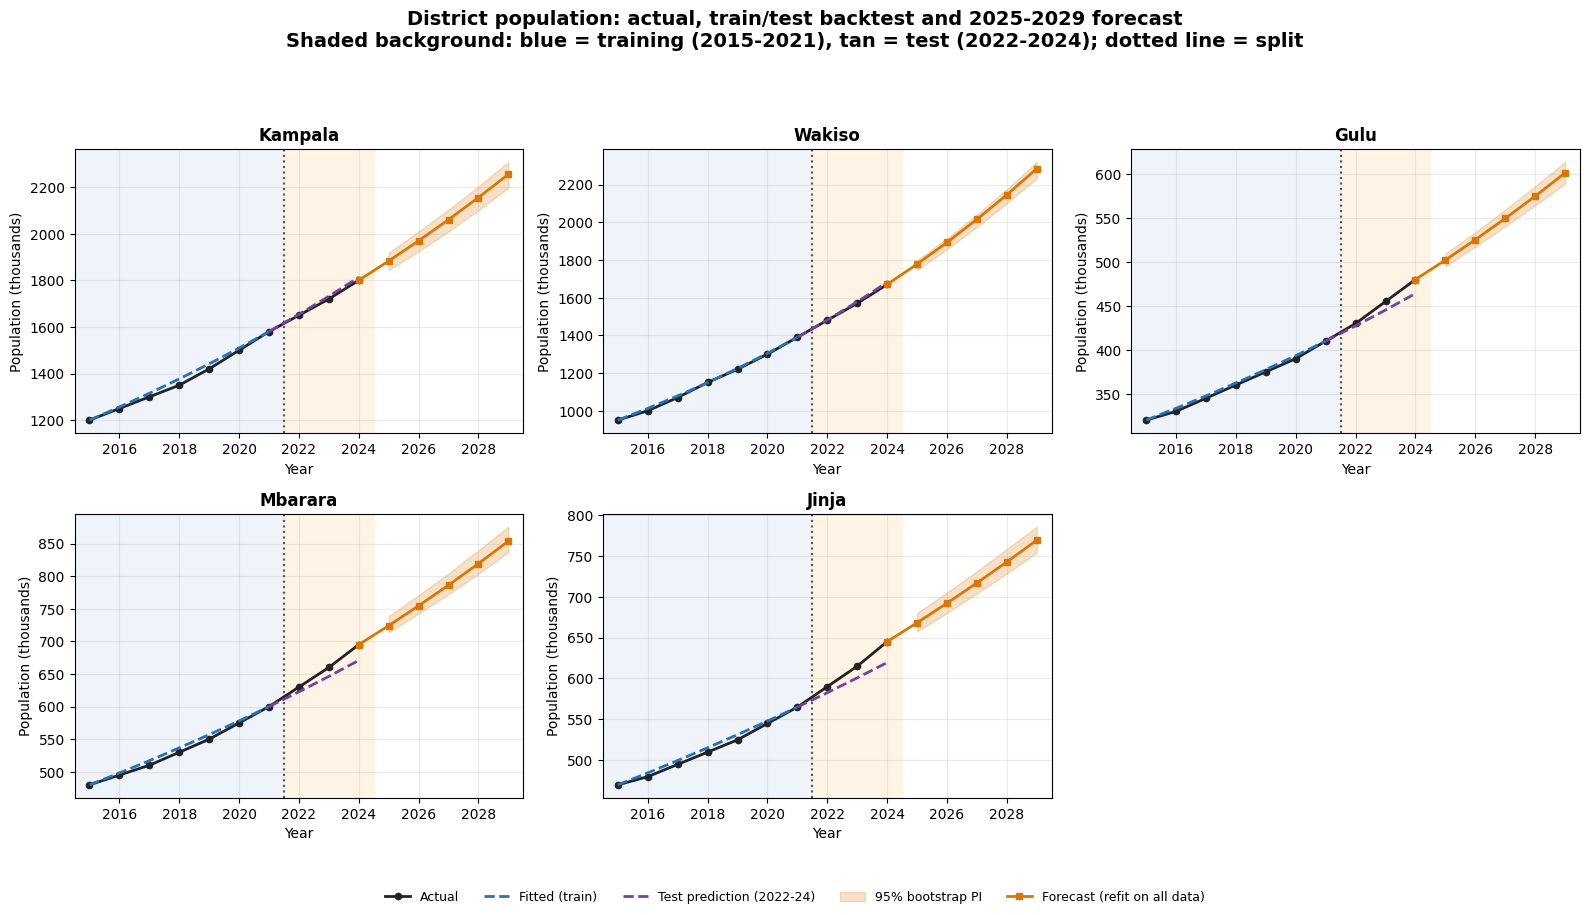

In [9]:
import os
os.makedirs("figures", exist_ok=True)
fig = plot_district_forecasts(districts, horizon=HORIZON, last_train_year=LAST_TRAIN_YEAR,
                              n_resamples=2000, seed=SEED,
                              models={name: factories[b] for name, b in best.items()})
fig.savefig("figures/district_forecasts.png", dpi=150, bbox_inches="tight")
plt.show()

Reading the figure: the test prediction (purple) hugs the actual series in every district, which is the visual version of the low CAGR MAPE in Task 5. The forecast bands are narrow, but see the limitations: they reflect only the small scatter of the historical data.

## Task 8: Planning output: additional classrooms by 2029

Assumptions: **18 %** of the population is primary-school age; a classroom holds **53** pupils; the number of classrooms needed in a year is rounded **up**; and today's (2024) stock of classrooms exactly meets 2024 need, so *additional classrooms = need(2029) − need(2024)*. Populations are in thousands, hence ×1,000.

In [10]:
rows = []
for d in districts:
    p24, p29 = d.populations[-1], forecasts[d.name][-1]
    rows.append({"District": d.name, "Pop 2024 (k)": p24, "Pop 2029 (k)": p29,
                 "Pupils 2024": p24 * 1000 * 0.18, "Pupils 2029": p29 * 1000 * 0.18,
                 "Classrooms 2024": classrooms_needed(p24), "Classrooms 2029": classrooms_needed(p29),
                 "Additional by 2029": additional_classrooms(p24, p29)})
class_df = pd.DataFrame(rows).set_index("District")
fmt = {c: "{:,.0f}" for c in class_df.columns if c != "Pop 2024 (k)" and c != "Pop 2029 (k)"}
display(class_df.style.format({**fmt, "Pop 2024 (k)": "{:,.1f}", "Pop 2029 (k)": "{:,.1f}"}))
print(f"Total additional classrooms across the five districts: {class_df['Additional by 2029'].sum():,}")

,Pop 2024 (k),Pop 2029 (k),Pupils 2024,Pupils 2029,Classrooms 2024,Classrooms 2029,Additional by 2029
District,,,,,,,
Kampala,"1,800.0","2,254.8","324,000","405,857","6,114","7,658","1,544"
Wakiso,"1,670.0","2,284.7","300,600","411,241","5,672","7,760","2,088"
Gulu,480.0,601.3,"86,400","108,229","1,631","2,043",412
Mbarara,695.0,853.7,"125,100","153,659","2,361","2,900",539
Jinja,645.0,769.0,"116,100","138,420","2,191","2,612",421


Total additional classrooms across the five districts: 5,004


**Wakiso needs the most (2,088)** even though Kampala is bigger today, because it grows faster; by 2029 the forecast puts Wakiso (2,285 k) just ahead of Kampala (2,255 k). Across the five districts about 5,000 extra classrooms are needed. If the planning unit is short of money, prioritising by *additional* classrooms (Wakiso, Kampala) rather than by current population gives a different order than ranking by size.

## Extension A: Bootstrap 95 % prediction intervals

Method (`src/bootstrap.py`, 2,000 resamples, seeded): take the CAGR fit's *relative* residuals (dropping the first and last, which are zero by construction because the curve passes through both endpoints), resample them to build a synthetic history, **refit CAGR** on it (parameter uncertainty), project forward, and apply a fresh resampled residual to each future year (noise). The 2.5th and 97.5th percentiles give the interval.

In [11]:
rows = []
for k, d in enumerate(districts):
    lo, hi = bootstrap_cagr_interval(d.years, d.populations, HORIZON, n_resamples=2000, seed=SEED + k)
    f = forecasts[d.name]
    rows.append({"District": d.name, "2029 point": f[-1], "2029 lower": lo[-1], "2029 upper": hi[-1],
                 "Half-width (% of point)": (hi[-1] - lo[-1]) / 2 / f[-1] * 100,
                 "2025 half-width (%)": (hi[0] - lo[0]) / 2 / f[0] * 100})
display(pd.DataFrame(rows).set_index("District"))

,2029 point,2029 lower,2029 upper,Half-width (% of point),2025 half-width (%)
District,,,,,
Kampala,"2,254.76","2,196.90","2,308.24",2.47,1.99
Wakiso,"2,284.67","2,233.52","2,320.61",1.91,1.43
Gulu,601.27,589.20,613.82,2.05,1.44
Mbarara,853.66,836.75,876.01,2.30,1.73
Jinja,769.00,753.71,785.66,2.08,1.68


The intervals widen with the horizon (half-width about 1.4–2.0 % of the forecast in 2025, 1.9–2.5 % in 2029). They are almost certainly **too narrow for planning**: they only capture the scatter seen in a smooth illustrative series using eight usable residuals, and none of the uncertainty about whether the growth rate itself will change.

## Extension B: Is the Fibonacci-ratio model defensible?

**No, not for population forecasting.** The ratios F(k+1)/F(k) run 1, 2, 1.5, 1.67, 1.6, … and converge to the golden ratio φ ≈ 1.618. Two readings of "scale by successive ratios" are possible and neither works:

- **Same base (default).** Every ratio multiplies the same last value, giving 1.0×, 2.0×, 1.5×, 1.67×, 1.6×: no growth, then a doubling, then a *fall* — a jagged path produced by how the sequence is indexed, not by demography.
- **Compounded.** Chaining the ratios gives the cumulative multiples 1, 2, 3, 5, 8 (the Fibonacci numbers themselves): Kampala would reach 14,400 thousand by 2029 (8× in five years), and in the long run growth of 61.8 % *every year*.

The model has no fitted parameter, so it ignores the data entirely; its holdout MAPE (~38 %) confirms that. It could be defensible only if there were a known mechanism that generates Fibonacci-like dynamics (e.g. an idealised, unconstrained breeding process with a fixed lag) *and* the rule were validated against history. Human populations at district level have no such mechanism. It is useful here only as a **benchmark that any serious model must beat**.

In [12]:
r = fibonacci_ratios(8)
display(pd.DataFrame({"k": np.arange(1, 9), "ratio F(k+1)/F(k)": r,
                      "cumulative multiple (compounded)": np.cumprod(r)}).set_index("k"))
print(f"golden ratio = {(1 + 5 ** 0.5) / 2:.4f}")

k = by_name["Kampala"]
print("Kampala 2029 -> CAGR:", round(forecasts["Kampala"][-1], 1),
      "| Fibonacci same base:", round(FibonacciRatioForecaster().fit(k.years, k.populations).predict(5)[-1], 1),
      "| Fibonacci compounded:", round(FibonacciRatioForecaster(True).fit(k.years, k.populations).predict(5)[-1], 1))

,ratio F(k+1)/F(k),cumulative multiple (compounded)
k,,
1,1.00,1.00
2,2.00,2.00
3,1.50,3.00
4,1.67,5.00
5,1.60,8.00
6,1.62,13.00
7,1.62,21.00
8,1.62,34.00


golden ratio = 1.6180
Kampala 2029 -> CAGR: 2254.8 | Fibonacci same base: 2880.0 | Fibonacci compounded: 14400.0


## Sanity checks (second method / hand calculation)

In [13]:
k = by_name["Kampala"]

# 1. Linear trend: np.polyfit vs scipy.stats.linregress (independent implementation)
lr = stats.linregress(k.years, k.populations)
lin = LinearTrendForecaster().fit(k.years, k.populations)
assert np.isclose(lr.slope, lin.slope) and np.isclose(lr.intercept, lin.intercept)

# 2. CAGR by hand: 1800 / 1200 = 1.5 over 9 years
assert np.isclose(k.cagr(), 1.5 ** (1 / 9) - 1)

# 3. Kampala CAGR test-set MAE recomputed with plain Python
train = k.populations[:7].tolist()
rate = (train[-1] / train[0]) ** (1 / 6) - 1
pred = [train[-1] * (1 + rate) ** s for s in (1, 2, 3)]
mae_hand = sum(abs(p - a) for p, a in zip(pred, k.populations[7:])) / 3
assert np.isclose(mae_hand, compare_models(k, factories)["CAGR"]["MAE"])

# 4. Classrooms by hand: 1,800,000 x 0.18 / 53 = 6,113.2 -> 6,114
assert classrooms_needed(1800) == 6114

print("All sanity checks passed.")

All sanity checks passed.


## Findings & Limitations

**Findings.** On the 2022–2024 hold-out the CAGR model was the most accurate in all five districts (MAPE 0.4–2.5 %), roughly 1.5 to 7 times more accurate than a linear trend, because these series grow geometrically rather than in a straight line. The Fibonacci-ratio model missed by 36–40 % and should not be used for planning. The forecasts put Wakiso (6.5 % a year) ahead of Kampala by 2029 (2,285 k vs 2,255 k) and imply about 5,000 additional classrooms across the five districts, the largest share in Wakiso (2,088) and Kampala (1,544).

**Limitations.** (1) The data are smooth and partly synthetic, and a three-point test set cannot separate models reliably; the 95 % bootstrap intervals (about ±2–2.5 % by 2029) reflect only past scatter and ignore migration, policy and census revisions, so they are too narrow. (2) Endpoint CAGR assumes one constant rate. In Gulu, Mbarara and Jinja recent growth (4.9–5.5 %) exceeds the ten-year average (3.6–4.6 %), so their classroom needs are probably understated. (3) The forecast's lower variance is an artefact of a shorter, noise-free series, not evidence of certainty. (4) Classroom counts assume a constant 18 % school-age share, 53 pupils per class and that today's classrooms exactly match today's need; any existing backlog would add to the total. Next steps: replace the illustrative data with UBOS census figures, and compare a log-linear regression fit to the endpoint CAGR.